# Urban discovery — selected actual research results
This executed preview displays saved study results. It fits no models and reads no private records.
The city-pattern PNG is a static figure: its underlying metropolitan table is withheld.
The estimate figure is regenerated from the six included model-level summary rows.

In [1]:
from pathlib import Path
import importlib.util
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "results").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "README.md").is_file()
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

def load_module(name):
    spec = importlib.util.spec_from_file_location(name, ROOT / "code" / (name + ".py"))
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

visuals = load_module("result_figures")

## Stored estimates and respondent-aggregation sensitivity

In [2]:
estimates = pd.read_csv(ROOT / "results" / "selected_associations.csv")
weights = pd.read_csv(ROOT / "results" / "selected_weighting_sensitivity.csv")
assert estimates.outcome.tolist() == ["learning", "low_sexuality_iat", "climate", "patents"]
assert weights.specification.tolist() == ["raw_unweighted_fixed", "national_weighted"]
assert len(estimates) == 4 and len(weights) == 2
display(estimates)
display(weights)

,outcome,estimate,ci_lower,ci_upper,metro_n
0,learning,0.333440,0.140697,0.526183,367
1,low_sexuality_iat,0.333537,0.172068,0.495005,342
2,climate,0.101638,0.050465,0.152810,374
3,patents,0.193363,0.075553,0.311173,378


,specification,estimate,ci_lower,ci_upper,metro_n
0,raw_unweighted_fixed,0.333440,0.140697,0.526183,367
1,national_weighted,0.082498,-0.139014,0.304010,367


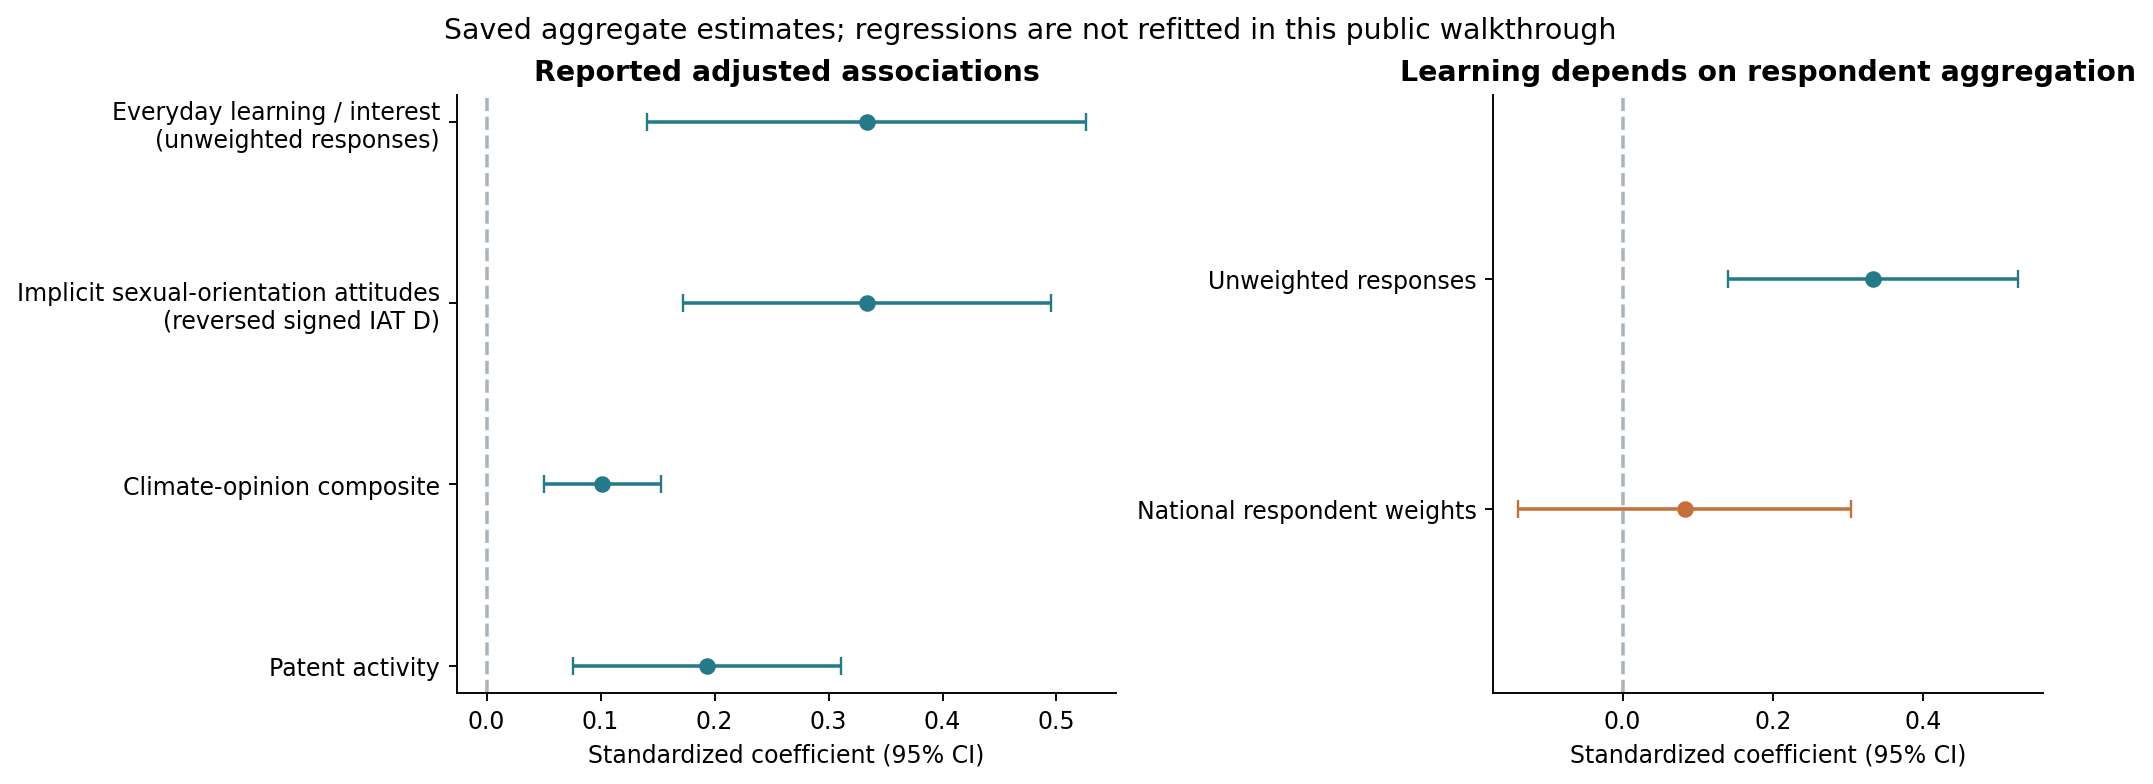

In [3]:
visuals.reported_associations(estimates, weights, FIGURES / "02_saved_associations.png")
display(Image(filename=str(FIGURES / "02_saved_associations.png")))

The weighted learning interval includes zero. Weights change respondent aggregation, not city regression weights.
These are stored adjusted associations. The implicit-attitude measure is specifically sexual-orientation IAT D, sign reversed.

## Actual metropolitan distribution (static selected figure)

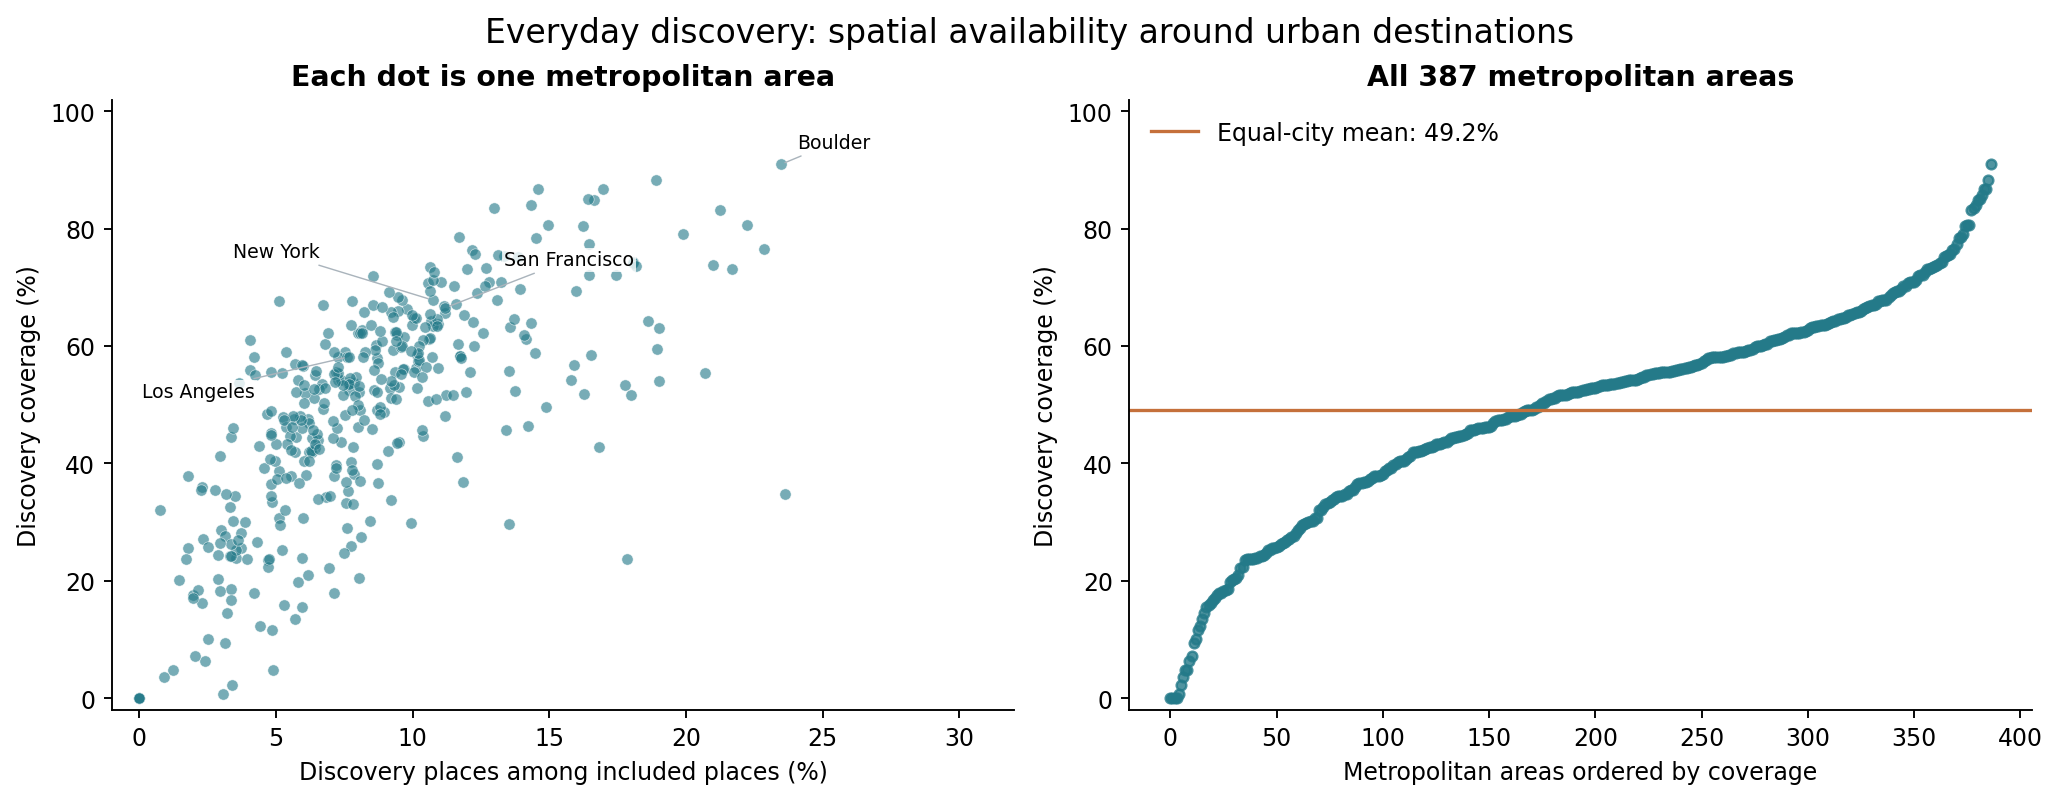

In [4]:
display(Image(filename=str(FIGURES / "01_actual_city_patterns.png")))

## Original analysis code for inspection
Importing these modules does not read data, refit regressions or reconstruct the private classifiers.
Their original numerical function bodies are retained.

In [5]:
normalization = load_module("text_normalization_excerpt")
assert callable(normalization.normalized_text)
estimation = load_module("estimation_excerpt")
geometry = load_module("spatial_coverage_excerpt")
assert all(callable(getattr(estimation, name)) for name in ["zscore", "ols", "cell"])
assert callable(geometry.build_reach)
summary = {"model_estimates": estimates.to_dict(orient="records"), "weighting": weights.to_dict(orient="records")}
(ROOT / "outputs").mkdir(exist_ok=True)
(ROOT / "outputs" / "selected_results_receipt.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Representative modules imported. No models were fitted and no private data were read.")

Representative modules imported. No models were fitted and no private data were read.
